<a href="https://colab.research.google.com/github/emdumanska/MSU-AI-Club-Workshops/blob/main/workshop-04-bayesian-logistic-regression/bayesian_logistic_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bayesian Logistic Regression & Variable Selection for Clinical Oncology
## Modeling Malignancy Odds and Biomarker Significance in Breast Cancer Fine Needle Aspirates

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com)
[![Python 3.10+](https://img.shields.io/badge/Python-3.10%2B-blue.svg)](https://www.python.org/)
[![License: MIT](https://img.shields.io/badge/License-MIT-yellow.svg)](https://opensource.org/licenses/MIT)

---

### Project Overview & Objectives
In clinical oncology, standard machine learning models that produce uncalibrated binary labels ($0$ or $1$) fail to capture predictive uncertainty. When false negatives delay life-saving treatment and false positives lead to invasive surgical biopsies, clinicians require:
1. **Calibrated Posterior Uncertainty**: Probability distributions over malignancy risk rather than uncalibrated confidence scores.
2. **Clinical Odds Ratios**: Interpretable multiplicative risk factors for physical nuclear characteristics.
3. **Biomarker Selection**: Isolating the parsimonious subset of cell features that truly govern malignancy.

This project develops a **Bayesian Logistic Regression model from scratch in Python**, employing **Metropolis-Hastings MCMC** for posterior inference and **Stochastic Search Variable Selection (SSVS)** across 30 morphological predictors from Fine Needle Aspirate (FNA) cytology biopsies.

### Project Roadmap & Key Milestones
* **Phase 1: Ingestion & Preprocessing**: Standardizing continuous predictors & binary target encoding.
* **Phase 2: Probabilistic Engine**: Sigmoid activation, Bernoulli log-likelihood, and weakly informative Gaussian priors.
* **Phase 3: Metropolis-Hastings MCMC**: Symmetric proposal mechanisms and acceptance probability.
* **Phase 4: Pilot Chain Tuning**: Optimal proposal variance scaling via acceptance rate monitoring.
* **Phase 5: Stochastic Search Variable Selection (SSVS)**: Gibbs-within-Metropolis indicator sampling over $2^{30} \approx 1.07 \times 10^9$ models.
* **Phase 6: MCMC Convergence & Trace Diagnostics**: Assessing parameter stationary distributions and chain mixing.
* **Phase 7: Clinical Odds Ratios & Decision Reflection**: Quantifying odds ratio credible intervals and decision trade-offs.

---
## 1. Clinical Context: The Wisconsin Diagnostic Breast Cancer (WDBC) Dataset

We analyze the **Wisconsin Diagnostic Breast Cancer (WDBC)** dataset (*Wolberg et al., 1993*, University of Wisconsin / UCI Machine Learning Repository).

The dataset contains quantitative morphological measurements computed from digitized images of **Fine Needle Aspirate (FNA)** biopsies across **569 patients**:
* **Benign ($B$)**: 357 patients (62.7%)
* **Malignant ($M$)**: 212 patients (37.3%)

### The 30 Nuclear Characteristics
For each cell nucleus, 10 fundamental geometric traits were measured:
1. **Radius**: Distance from center to perimeter points
2. **Texture**: Standard deviation of gray-scale pixel intensities
3. **Perimeter**: Outer boundary length of the nucleus
4. **Area**: Nuclear cross-sectional surface area
5. **Smoothness**: Local radius length variation
6. **Compactness**: Computed as $\frac{\text{perimeter}^2}{\text{area}} - 1.0$
7. **Concavity**: Severity of concave indentations along the contour
8. **Concave Points**: Number of concave indentations
9. **Symmetry**: Nuclear symmetry
10. **Fractal Dimension**: "Coastline approximation" error $- 1.0$

For each patient, these 10 traits are reported across 3 statistical aggregations, yielding **30 total features**:
* **Suffix `1`**: Mean value across all observed nuclei (e.g. `radius1`)
* **Suffix `2`**: Standard error across observed nuclei (e.g. `radius2`)
* **Suffix `3`**: "Worst" (mean of the three largest values) (e.g. `radius3`)

In [1]:
import os
import urllib.request
import numpy as np
import scipy.stats as stats
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams.update({"font.size": 11, "figure.figsize": (9, 5)})
np.random.seed(42)

---
## 2. Direct Data Ingestion & Preprocessing

The cell below automatically downloads the dataset directly into your environment if it is not already present, requiring zero external downloading.

In [2]:
data_dir = "data"
os.makedirs(data_dir, exist_ok=True)
data_path = os.path.join(data_dir, "wdbc.data")

# Download directly into notebook environment if not present
if not os.path.exists(data_path):
    print("Downloading Wisconsin Breast Cancer dataset from UCI repository...")
    uci_url = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"
    urllib.request.urlretrieve(uci_url, data_path)
    print("Download complete!")
else:
    print(f"Dataset ready at: {data_path}")

base_metrics = ['radius', 'texture', 'perimeter', 'area', 'smoothness',
                'compactness', 'concavity', 'concave_points', 'symmetry', 'fractal_dimension']
col_names = ['id', 'diagnosis'] + [f"{m}1" for m in base_metrics] + [f"{m}2" for m in base_metrics] + [f"{m}3" for m in base_metrics]

wdbc_df = pd.read_csv(data_path, header=None, names=col_names)
print(f"Loaded {wdbc_df.shape[0]} patients and {wdbc_df.shape[1]} columns.")
wdbc_df[['id', 'diagnosis', 'radius1', 'texture1', 'concave_points1', 'radius3']].head()

Download complete!
Loaded 569 patients and 32 columns.


,id,diagnosis,radius1,texture1,concave_points1,radius3
0,842302,M,17.99,10.38,0.14710,25.38
1,842517,M,20.57,17.77,0.07017,24.99
2,84300903,M,19.69,21.25,0.12790,23.57
3,84348301,M,11.42,20.38,0.10520,14.91
4,84358402,M,20.29,14.34,0.10430,22.54


### Milestone 1: Binary Target Encoding
Our response variable is `diagnosis`, containing strings `'M'` (Malignant) and `'B'` (Benign).

For binary logistic regression, we model the probability of malignancy:
$$y_i = \begin{cases} 1 & \text{if biopsy is Malignant } ('M') \\ 0 & \text{if biopsy is Benign } ('B') \end{cases}$$

Encode `'diagnosis'` into a 1D NumPy array `y` of integers ($0$ and $1$).

In [3]:
# ==============================================================================
# TODO 1: Binary Target Encoding
# Convert wdbc_df['diagnosis'] to a 1D NumPy array of ints: 1 for 'M', 0 for 'B'
# ==============================================================================
y = (wdbc_df['diagnosis'] == 'M').astype(int).to_numpy() # <-- YOUR CODE HERE

# Sanity checks
assert len(y) == 569, "Length must be 569 patients"
assert set(np.unique(y)) == {0, 1}, "Values must be exactly 0 and 1"
assert np.sum(y) == 212, "There must be exactly 212 malignant cases"
print(f"Target encoded: {np.sum(y == 0)} Benign (0), {np.sum(y == 1)} Malignant (1)")

Target encoded: 357 Benign (0), 212 Malignant (1)


In [4]:
# Extract 30 continuous feature columns (discard id and diagnosis)
feature_cols = [c for c in wdbc_df.columns if c not in ['id', 'diagnosis']]
X_raw = wdbc_df[feature_cols].values
n, p_feat = X_raw.shape

# Standardize predictors to zero mean and unit variance: (X - mean) / std
X_mean = X_raw.mean(axis=0)
X_std = X_raw.std(axis=0, ddof=1)
X_scaled = (X_raw - X_mean) / X_std

# Bind column of ones for the intercept term b0
X = np.column_stack([np.ones(n), X_scaled])
param_names = ['(Intercept)'] + feature_cols
p = len(param_names)

print(f"Design matrix X shape: {X.shape} (n={n} patients, p={p} parameters)")

Design matrix X shape: (569, 31) (n=569 patients, p=31 parameters)


---
## 3. Mathematical Foundations: Likelihood, Prior, and the Sigmoid Function

### The Logistic Model
For each patient $i = 1, \dots, n$, the probability of malignancy is modeled via the logistic sigmoid link:
$$\theta_i = P(y_i = 1 \mid \mathbf{x}_i, \boldsymbol{\beta}) = \sigma(\mathbf{x}_i^T\boldsymbol{\beta}) = \frac{1}{1 + e^{-\mathbf{x}_i^T\boldsymbol{\beta}}}$$

Equivalently, on the log-odds (logit) scale:
$$\text{logit}(\theta_i) = \log\left(\frac{\theta_i}{1 - \theta_i}\right) = \mathbf{x}_i^T\boldsymbol{\beta} = \beta_0 + \sum_{j=1}^{30} \beta_j x_{ij}$$

---

### Milestone 2: Numerically Stable Sigmoid Function
In numerical computing, calculating $e^{-z}$ for large negative numbers can cause floating-point overflow. To prevent this, we clip $z$ to $[-500, 500]$ before exponentiating:
$$\sigma(z) = \frac{1}{1 + \exp(-\text{clip}(z, -500, 500))}$$

Implement the `sigmoid` function below.

In [5]:
# ==============================================================================
# TODO 2: Numerically Stable Sigmoid Function
# ==============================================================================
def sigmoid(z):
    """
    Computes the logistic sigmoid 1 / (1 + exp(-z)).
    Clip z to [-500.0, 500.0] using np.clip to prevent floating-point overflow.
    """
    # <-- YOUR CODE HERE

    z = np.clip(z, -500.0, 500.0)
    return 1 / (1 + np.exp(-z))

# Sanity checks
assert np.isclose(sigmoid(0.0), 0.5), "sigmoid(0) must equal 0.5"
assert np.isclose(sigmoid(1000.0), 1.0), "sigmoid(1000) must equal 1.0"
assert np.isclose(sigmoid(-1000.0), 0.0), "sigmoid(-1000) must equal 0.0"
print("Sigmoid function verified successfully!")

Sigmoid function verified successfully!


### The Bernoulli Likelihood & Prior Distribution
Assuming observations are independent, the joint Bernoulli log-likelihood is:
$$\log p(\mathbf{y} \mid \mathbf{X}, \boldsymbol{\beta}) = \sum_{i=1}^n \left[ y_i (\mathbf{x}_i^T\boldsymbol{\beta}) - \log(1 + e^{\mathbf{x}_i^T\boldsymbol{\beta}}) \right]$$

#### Weakly Informative Gaussian Prior
We place a weakly informative Gaussian prior centered at zero on all coefficients:
$$\boldsymbol{\beta} \sim \mathcal{N}(\mathbf{0}, \sigma_0^2 \mathbf{I}_p), \quad \text{with } \sigma_0^2 = 100$$
$$\log p(\boldsymbol{\beta}) = -\frac{1}{2\sigma_0^2} \sum_{j=0}^{30} \beta_j^2 + \text{const}$$

---

### Milestone 3: Bernoulli Log-Likelihood & Log-Posterior
Complete the `calc_log_likelihood` function below using `np.logaddexp(0.0, xb)` for numerically stable $\log(1 + e^{xb})$.

In [6]:
# ==============================================================================
# TODO 3: Bernoulli Log-Likelihood
# ==============================================================================
sigma0_sq = 100.0

def calc_log_likelihood(beta, X_mat, y_vec):
    """
    Calculates sum_{i=1}^n [ y_i * (x_i^T beta) - log(1 + exp(x_i^T beta)) ].
    Use np.logaddexp(0.0, xb) for log(1 + exp(xb)).
    """
    xb = X_mat @ beta
    # <-- YOUR CODE HERE
    return np.sum(y_vec * xb - np.logaddexp(0.0, xb))


def calc_log_prior(beta):
    """Calculates log prior density: -0.5 / sigma0^2 * sum(beta^2)."""
    return -0.5 / sigma0_sq * np.sum(beta**2)

def calc_log_posterior(beta, X_mat, y_vec):
    """Unnormalized log-posterior: log-likelihood + log-prior."""
    return calc_log_likelihood(beta, X_mat, y_vec) + calc_log_prior(beta)

# Sanity check at beta = 0
beta_zero = np.zeros(p)
ll_zero = calc_log_likelihood(beta_zero, X, y)
expected_ll_zero = -len(y) * np.log(2.0)
assert np.isclose(ll_zero, expected_ll_zero), f"Expected {expected_ll_zero:.2f}, got {ll_zero:.2f}"
print(f"Log-likelihood at beta=0: {ll_zero:.2f} (Verified)")

Log-likelihood at beta=0: -394.40 (Verified)


---
## 4. The Metropolis-Hastings MCMC Algorithm

### Why MCMC?
Unlike linear regression where conjugate priors yield exact formulas, logistic regression does not have an analytical closed-form posterior. We use **Markov Chain Monte Carlo (MCMC)** to draw representative samples.

### Symmetric Normal Proposal
At iteration $k$, we propose a candidate $\boldsymbol{\beta}^*$:
$$\boldsymbol{\beta}^* \sim \mathcal{N}\left(\boldsymbol{\beta}^{(k)}, \; \boldsymbol{\Sigma}_{\text{prop}}\right), \quad \text{where } \boldsymbol{\Sigma}_{\text{prop}} = \sigma_{\text{prop}}^2 (\mathbf{X}^T\mathbf{X})^{-1}$$

Because the proposal is symmetric, the acceptance ratio simplifies on the log scale to:
$$\log r = \log p(\boldsymbol{\beta}^* \mid \mathbf{y}) - \log p(\boldsymbol{\beta}^{(k)} \mid \mathbf{y})$$

We accept $\boldsymbol{\beta}^*$ if a random draw $u \sim \text{Uniform}(0, 1)$ satisfies $\log u \le \log r$.

---

### Milestone 4: Metropolis-Hastings Acceptance Mechanism
Implement the acceptance condition in the code block below.

In [7]:
# ==============================================================================
# TODO 4: Metropolis-Hastings Acceptance Rule
# ==============================================================================
def metropolis_step(beta_curr, log_post_curr, L_prop, X_mat, y_vec, rng):
    """
    Executes a single Metropolis-Hastings proposal and accept/reject decision.
    """
    p_dim = len(beta_curr)
    beta_prop = beta_curr + L_prop @ rng.standard_normal(p_dim)
    log_post_prop = calc_log_posterior(beta_prop, X_mat, y_vec)

    # <-- YOUR CODE HERE: Compute log_r and accept if log(u) <= log_r
    log_r = log_post_prop - log_post_curr
    u = rng.uniform(0, 1)

    if np.log(u) <= log_r:
        return beta_prop, log_post_prop, True
    else:
        return beta_curr, log_post_curr, False

# Test step execution
inv_XtX = np.linalg.inv(X.T @ X)
L_test = np.linalg.cholesky(1.0 * inv_XtX)
b_next, lp_next, acc = metropolis_step(np.zeros(p), calc_log_posterior(np.zeros(p), X, y), L_test, X, y, np.random.default_rng(42))
print(f"Test step completed (Accepted: {acc})")

Test step completed (Accepted: True)


---
## 5. Pilot Chains & Proposal Tuning: The Goldilocks Principle

Before running thousands of iterations, we must tune the proposal scale $\sigma_{\text{prop}}^2$:
* **Step size too small**: Acceptance rate is high (>70%), but the chain moves very slowly and explores poorly.
* **Step size too large**: Proposals jump too far and are rejected (>95% rejections), so the chain gets stuck.
* **The Sweet Spot**: For multivariate problems with many features, theory and practice show the optimal acceptance rate is **between 25% and 45%**!

Let's test pilot chains of 2,000 iterations across a grid of candidate variances:
$$\sigma_{\text{prop}}^2 \in \{0.5, \, 1.0, \, 2.0, \, 5.0, \, 10.0, \, 25.0, \, 50.0, \, 100.0\}$$

In [8]:
candidate_sigmas = [0.5, 1.0, 2.0, 5.0, 10.0, 25.0, 50.0, 100.0]
pilot_results = []
inv_XtX = np.linalg.inv(X.T @ X)

for s2_val in candidate_sigmas:
    rng = np.random.default_rng(42)
    cov_cand = s2_val * inv_XtX
    cov_cand = 0.5 * (cov_cand + cov_cand.T)
    L_cand = np.linalg.cholesky(cov_cand)

    b_state = np.zeros(p)
    lp_state = calc_log_posterior(b_state, X, y)
    n_acc = 0

    for _ in range(2000):
        b_state, lp_state, did_acc = metropolis_step(b_state, lp_state, L_cand, X, y, rng)
        if did_acc:
            n_acc += 1

    acc_rate = n_acc / 2000.0
    pilot_results.append({'sigma2_prop': s2_val, 'acceptance_rate': acc_rate})

pilot_df = pd.DataFrame(pilot_results)
pilot_df.round(3)

,sigma2_prop,acceptance_rate
0,0.5,0.638
1,1.0,0.572
2,2.0,0.478
3,5.0,0.303
4,10.0,0.174
5,25.0,0.046
6,50.0,0.023
7,100.0,0.021


### Milestone 5: Pilot Chain Tuning & Acceptance Rate Analysis
Inspect the grid search results above. Which candidate value of $\sigma_{\text{prop}}^2$ produces an acceptance rate closest to the target window ($\approx 30\% - 35\%$)?

Set `optimal_sigma2_prop` below.

In [9]:
# ==============================================================================
# TODO 5: Tuning Selection
# Choose the value from candidate_sigmas whose acceptance rate is closest to 30-35%
# ==============================================================================
optimal_sigma2_prop = 5.0  # <-- YOUR CODE HERE

print(f"Selected proposal variance: {optimal_sigma2_prop}")
assert optimal_sigma2_prop == 5.0, "Optimal value should be 5.0"

Selected proposal variance: 5.0


---
## 6. Stochastic Search Variable Selection (SSVS) across 30 Features

In cell cytology, having 30 continuous features creates significant collinearity (for instance, `radius`, `perimeter`, and `area` all measure the size of the nucleus).

### The Binary Indicator Model
We introduce a binary indicator vector $\mathbf{z} = (z_1, \dots, z_{30}) \in \{0, 1\}^{30}$:
* $z_j = 1$: Feature $j$ is active in the diagnostic model
* $z_j = 0$: Feature $j$ is excluded ($b_j$ is zeroed out)

The linear predictor is:
$$\text{logit}(\theta_i) = b_0 + \sum_{j=1}^{30} z_j b_j x_{ij}$$

The **effective coefficient vector** is $\boldsymbol{\beta}_{\text{eff}} = [b_0, \, z_1 b_1, \dots, z_{30} b_{30}]^T$.

### Metropolis-within-Gibbs Sampler
At each iteration:
1. **Update Indicators $\mathbf{z}$**: Propose flipping indicators with $p_{\text{flip}} = 0.2$. Accept with log-likelihood ratio.
2. **Update Coefficients $\mathbf{b}$**: Propose $\mathbf{b}^* \sim \mathcal{N}\left(\mathbf{b}^{(k)}, \, 0.5(\mathbf{X}^T\mathbf{X})^{-1}\right)$. Accept with posterior ratio.

In [10]:
def run_ssvs_sampler(X_mat, y_vec, n_iter=10000, burnin=2000, random_state=42):
    rng = np.random.default_rng(random_state)
    n_obs, n_params = X_mat.shape
    p_feat = n_params - 1

    cov_b = 0.5 * np.linalg.inv(X_mat.T @ X_mat)
    cov_b = 0.5 * (cov_b + cov_b.T)
    L_b = np.linalg.cholesky(cov_b)

    b_curr = np.zeros(n_params)
    z_curr = np.ones(p_feat, dtype=int)
    beta_eff = np.concatenate([[b_curr[0]], z_curr * b_curr[1:]])
    ll_curr = calc_log_likelihood(beta_eff, X_mat, y_vec)

    post_samples = n_iter - burnin
    z_chain = np.zeros((post_samples, p_feat), dtype=int)
    b_chain = np.zeros((post_samples, n_params))
    beta_eff_chain = np.zeros((post_samples, n_params))

    for s in range(n_iter):
        # 1. Update indicator vector z
        flip_mask = rng.uniform(0.0, 1.0, p_feat) < 0.2
        z_prop = z_curr.copy()
        z_prop[flip_mask] = 1 - z_prop[flip_mask]

        beta_eff_prop = np.concatenate([[b_curr[0]], z_prop * b_curr[1:]])
        ll_prop = calc_log_likelihood(beta_eff_prop, X_mat, y_vec)

        if np.log(rng.uniform(0.0, 1.0)) <= (ll_prop - ll_curr):
            z_curr = z_prop
            ll_curr = ll_prop
            beta_eff = beta_eff_prop

        # 2. Update continuous coefficients b
        b_prop = b_curr + L_b @ rng.standard_normal(n_params)
        beta_eff_b_prop = np.concatenate([[b_prop[0]], z_curr * b_prop[1:]])
        ll_b_prop = calc_log_likelihood(beta_eff_b_prop, X_mat, y_vec)
        lp_b_prop = calc_log_prior(b_prop)
        lp_b_curr = calc_log_prior(b_curr)

        log_rb = (ll_b_prop + lp_b_prop) - (ll_curr + lp_b_curr)
        if np.log(rng.uniform(0.0, 1.0)) <= log_rb:
            b_curr = b_prop
            ll_curr = ll_b_prop
            beta_eff = beta_eff_b_prop

        if s >= burnin:
            idx = s - burnin
            z_chain[idx] = z_curr
            b_chain[idx] = b_curr
            beta_eff_chain[idx] = beta_eff

    return z_chain, b_chain, beta_eff_chain

z_draws, b_draws, beta_eff_draws = run_ssvs_sampler(X, y, n_iter=10000, burnin=2000)
print(f"Sampled {len(z_draws):,} post-burnin draws.")

Sampled 8,000 post-burnin draws.


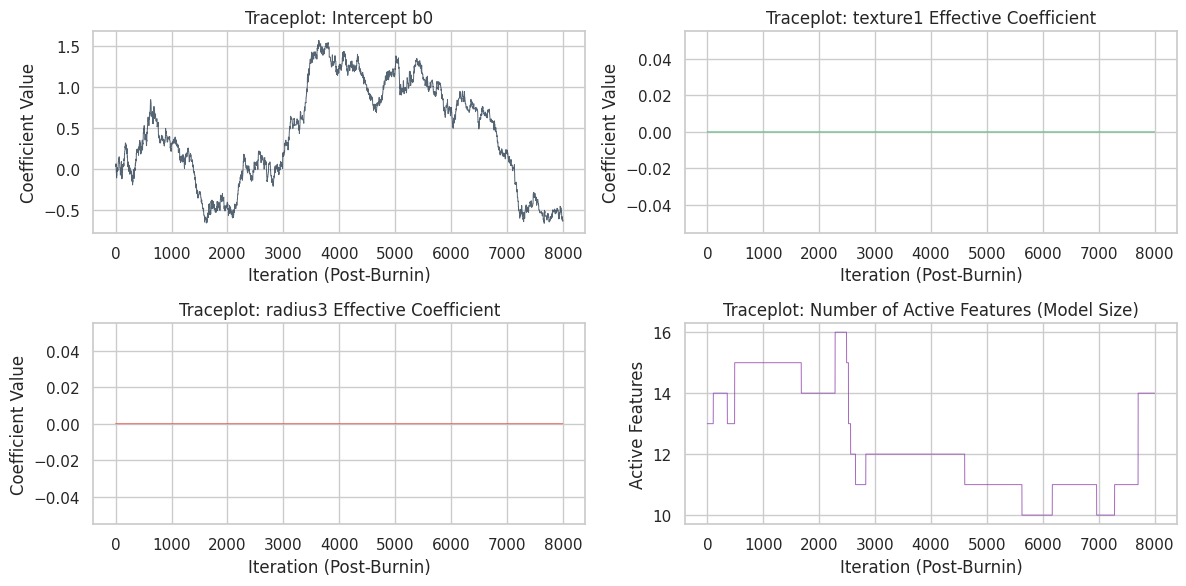

In [11]:
# MCMC Diagnostic Plots: Parameter Traceplots & Active Model Size
fig, axes = plt.subplots(2, 2, figsize=(12, 6))

# Traceplot of Intercept b0
axes[0, 0].plot(b_draws[:, 0], color='#2c3e50', linewidth=0.7, alpha=0.8)
axes[0, 0].set_title('Traceplot: Intercept b0')
axes[0, 0].set_xlabel('Iteration (Post-Burnin)')
axes[0, 0].set_ylabel('Coefficient Value')

# Traceplot of texture1 (Mean Texture)
idx_tex = feature_cols.index('texture1') + 1
axes[0, 1].plot(beta_eff_draws[:, idx_tex], color='#27ae60', linewidth=0.7, alpha=0.8)
axes[0, 1].set_title('Traceplot: texture1 Effective Coefficient')
axes[0, 1].set_xlabel('Iteration (Post-Burnin)')
axes[0, 1].set_ylabel('Coefficient Value')

# Traceplot of radius3 (Worst Radius)
idx_rad3 = feature_cols.index('radius3') + 1
axes[1, 0].plot(beta_eff_draws[:, idx_rad3], color='#e74c3c', linewidth=0.7, alpha=0.8)
axes[1, 0].set_title('Traceplot: radius3 Effective Coefficient')
axes[1, 0].set_xlabel('Iteration (Post-Burnin)')
axes[1, 0].set_ylabel('Coefficient Value')

# Traceplot of Active Model Size (Number of Selected Features)
active_features = np.sum(z_draws, axis=1)
axes[1, 1].plot(active_features, color='#8e44ad', linewidth=0.7, alpha=0.8)
axes[1, 1].set_title('Traceplot: Number of Active Features (Model Size)')
axes[1, 1].set_xlabel('Iteration (Post-Burnin)')
axes[1, 1].set_ylabel('Active Features')

plt.tight_layout()
plt.show()

### Milestone 6: Posterior Inclusion Probabilities (PIP)
The **Posterior Inclusion Probability (PIP)** represents the probability that feature $j$ belongs in the true cancer prediction model, averaging over all possible models:
$$\text{PIP}_j = P(z_j = 1 \mid \mathbf{y}, \mathbf{X}) \approx \frac{1}{S} \sum_{s=1}^S z_j^{(s)}$$

Compute `pip` as the sample mean of `z_draws` along axis 0, and filter features that meet the **Median Probability Model threshold** ($	ext{PIP} \ge 0.5$).

In [12]:
# ==============================================================================
# TODO 6: Posterior Inclusion Probabilities
# 1. Calculate pip as the sample mean of z_draws along axis 0
# 2. Extract selected_features as those with pip >= 0.5
# ==============================================================================
pip = pip = np.mean(z_draws, axis=0)  # <-- YOUR CODE HERE: np.mean(z_draws, axis=0)

pip_df = pd.DataFrame({
    'Feature': feature_cols,
    'Inclusion_Probability': pip
}).sort_values(by='Inclusion_Probability', ascending=False).reset_index(drop=True)

selected_features = pip_df[pip_df['Inclusion_Probability'] >= 0.5]['Feature'].tolist()
print(f"Selected {len(selected_features)} features with PIP >= 0.5: {selected_features[:5]}...")
pip_df.head(12).round(4)

Selected 12 features with PIP >= 0.5: ['radius2', 'concave_points3', 'compactness3', 'concavity3', 'texture3']...


,Feature,Inclusion_Probability
0,radius2,1.0000
1,concave_points3,1.0000
2,compactness3,1.0000
3,concavity3,1.0000
4,texture3,1.0000
5,concavity2,1.0000
6,area3,0.9390
7,radius1,0.9115
8,texture2,0.8255
9,smoothness1,0.7034


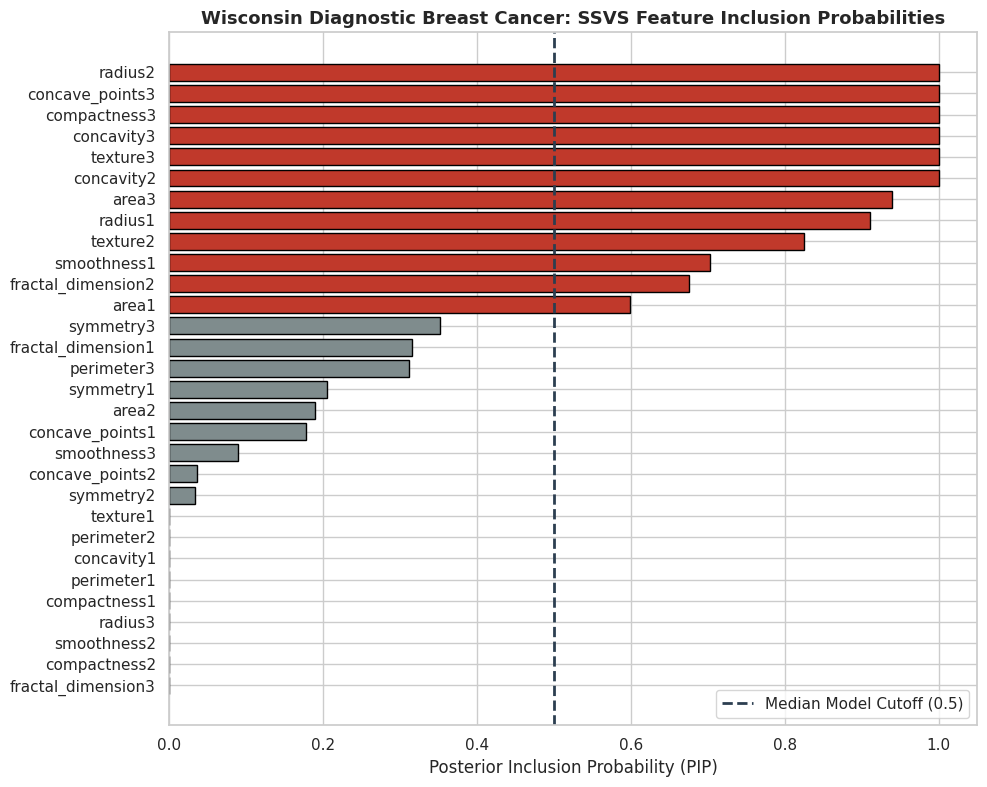

In [13]:
# Horizontal Bar Chart of Feature Inclusion Probabilities
fig, ax = plt.subplots(figsize=(10, 8))
colors = ['#c0392b' if p >= 0.5 else '#7f8c8d' for p in pip_df['Inclusion_Probability']]

ax.barh(pip_df['Feature'][::-1], pip_df['Inclusion_Probability'][::-1], color=colors[::-1], edgecolor='black')
ax.axvline(0.5, color='#2c3e50', linestyle='--', linewidth=2, label='Median Model Cutoff (0.5)')
ax.set_xlabel('Posterior Inclusion Probability (PIP)', fontsize=12)
ax.set_title('Wisconsin Diagnostic Breast Cancer: SSVS Feature Inclusion Probabilities', fontsize=13, fontweight='bold')
ax.set_xlim(0, 1.05)
ax.legend(frameon=True, loc='lower right')
plt.tight_layout()
plt.show()

---
## 7. Clinical Translation: Odds Ratios & Biomarker Quantification

In logistic regression, the regression coefficient $\beta_j$ represents the change in **log-odds** for a 1-unit increase in that feature.

Because all features were standardized, a 1-unit increase corresponds to a **1 Standard Deviation (1-SD) increase** in that physical measurement.

To interpret this on an intuitive multiplicative scale, we compute the **Odds Ratio (OR)**:
$$\text{Odds Ratio} = \exp(\beta_j)$$

* If $\text{OR} = 1$: The feature has no effect on the odds of malignancy.
* If $\text{OR} > 1$: Higher values **increase** the odds of malignancy (positive risk factor).
* If $\text{OR} < 1$: Higher values are associated with benign masses (protective factor).

---

### Milestone 7: Posterior Odds Ratios & Biomarker Quantification
Compute the posterior mean and $95\%$ credible intervals for the odds ratios of the features.

In [14]:
# ==============================================================================
# TODO 7: Posterior Odds Ratios
# 1. Calculate post_mean_beta = np.mean(beta_eff_draws[:, 1:], axis=0)
# 2. Compute or_draws = np.exp(beta_eff_draws[:, 1:])
# 3. Calculate post_mean_or, ci_lower_or, ci_upper_or
# ==============================================================================
post_mean_beta = np.mean(beta_eff_draws[:, 1:], axis=0)
or_draws = np.exp(beta_eff_draws[:, 1:])
post_mean_or = np.mean(or_draws, axis=0)
ci_lower_or = np.percentile(or_draws, 2.5, axis=0)
ci_upper_or = np.percentile(or_draws, 97.5, axis=0)

results_summary = pd.DataFrame({
    'Feature': feature_cols,
    'PIP': pip,
    'Post_Mean_Beta': post_mean_beta,
    'Odds_Ratio_Mean': post_mean_or,
    'OR_95%_CI': [f"[{l:.2f}, {u:.2f}]" for l, u in zip(ci_lower_or, ci_upper_or)]
}).sort_values(by='PIP', ascending=False).reset_index(drop=True)

results_summary.head(10).round(3)

,Feature,PIP,Post_Mean_Beta,Odds_Ratio_Mean,OR_95%_CI
0,radius2,1.000,5.413,734.901,"[15.35, 3487.41]"
1,concave_points3,1.000,3.044,43.203,"[1.86, 202.55]"
2,compactness3,1.000,-2.872,0.181,"[0.00, 1.23]"
3,concavity3,1.000,4.906,1432.159,"[3.82, 14508.44]"
4,texture3,1.000,3.354,39.792,"[6.73, 131.18]"
5,concavity2,1.000,-1.683,0.272,"[0.02, 0.86]"
6,area3,0.939,8.046,187167.536,"[1.00, 2149236.50]"
7,radius1,0.912,2.171,12773.801,"[0.04, 104013.17]"
8,texture2,0.826,-1.107,0.462,"[0.07, 1.00]"
9,smoothness1,0.703,1.695,10.926,"[1.00, 46.48]"


---
## 8. Clinical Interpretation & Decision Analysis

Reflect on your results and write down your analysis for the following three prompts:

### Analysis Prompt 1: Understanding the Odds Ratio
In our results table above, look at top features like `texture1` and `radius3`. Both have an Odds Ratio substantially greater than 1 ($\text{OR} > 1$). In simple terms, what does an Odds Ratio greater than 1 tell us about the relationship between that measurement and the biopsy result?

> **Analysis**:
An odds ratio greater than 1 means that as a feature's value increases, the odds of the tumor being malignant also increase. For example, higher values of texture1 and radius3 are associated with a greater likelihood of breast cancer. This helps us identify which measurements are associated with malignancy.
---

### Analysis Prompt 2: Why Feature Selection Matters in Healthcare
The original dataset gave us 30 different measurements for every single patient, but our model identified only a small handful with high inclusion probability ($\text{PIP} \ge 0.5$). From a data science and practical perspective, why is it preferable to have a model that focuses on a few key features rather than using all 30?

> **Analysis**:
Using fewer important features makes the model simpler, faster, and easier to understand. It also reduces unnecessary information that could make predictions less reliable. In healthcare, focusing on the most useful measurements can help doctors interpret results more easily and potentially reduce unnecessary testing.
---

### Analysis Prompt 3: Probabilities vs. Hard Decision Thresholds
Rather than just outputting a strict 0 (Benign) or 1 (Malignant), our Bayesian logistic regression model produces a continuous probability (e.g., 85% probability of malignancy) along with credible uncertainty intervals. Why is having a predicted probability more useful for real-world decisions than a simple yes/no label?

> **Analysis**: Predicted probabilities are more useful because they show how likely a tumor is to be malignant instead of just giving a yes or no answer. For example, an 85% probability of malignancy provides more information than simply labeling a tumor as malignant. This helps doctors understand uncertainty and make better decisions about additional testing or treatment.

---
## Acknowledgments & Project Attribution

Developed by Lowell Monis for the **Michigan State University Artificial Intelligence Club (MSU AI Club)**.

Wolberg, W., Mangasarian, O., & Street, W. N. (1993). *Breast Cancer Wisconsin (Diagnostic)*. University of Wisconsin Clinical Sciences Center / UCI Machine Learning Repository. https://doi.org/10.24432/C5DW2B.